# 07 · Suggestions model: "Travellers like you also added"

**Question:** once someone has picked a few sights, which sight are they most likely to add next?

Until now the planner answered this by counting: for every pair of sights, the % of trips with the first that also have the second, averaged over the sights already picked. That only ever looks at **pairs**, and it can't use anything else the traveller told us. A small neural network sees the whole trip at once, plus the interests the traveller ticked in the planner (History, Art, Sea & islands...).

**Training trick:** take a trip, hide one of its sights, and ask the model to guess the hidden one from the rest. Every trip gives one example per sight.

**Plan**
1. Load the trips (the 3,000 sample trips the app uses, plus real saved trips if there are any)
2. Split by trip and build hide-one-sight examples
3. Baselines: popularity, and the counting method the app uses now
4. Keras MLP: picked sights + ticked interests in, a probability for every sight out (three sizes, chosen on validation)
5. Compare on test trips, with and without interests ticked (hit@3: is the hidden sight in the top 3?)
6. A few examples, then save the weights for the app

In [1]:
import json, random, sqlite3, warnings
from math import hypot
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split

ROOT = Path("..").resolve()
MODELS = ROOT / "models"
FIGS = ROOT / "reports" / "figures"
SIGHTS = ROOT / "app" / "demo_data" / "mon.json"
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
keras.utils.set_random_seed(SEED)

I0000 00:00:1791978004.667893   14436 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791978004.708225   14436 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791978005.849208   14436 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. The trips
**Sample trips.** The app has no real history yet, so its counting uses 3,000 sample trips. Each one is made the same way as in the app's `cooc.json` (same seed): a traveller likes 1 to 3 interests, plans 3 to 10 sights, sights that match their interests are 5× more likely, popular sights are more likely, and a sight next to one already picked is 1.8× more likely.

Each sample trip also keeps the interests its traveller had, as the ticked chips would be in the planner.

**Real trips.** Every time someone plans their days, the app stores the sights and, from now on, the ticked interests (`events` table, kind `pick`). Locally that's `data/usage.sqlite`; the deployed app keeps them in its online database. Real trips count once per person and trip.

In [2]:
mon = json.load(open(SIGHTS, encoding="utf-8"))
names = [m["n"] for m in mon]
N = len(mon)
INT = ["history", "architecture", "food", "views", "sea", "art", "local"]   # the planner's interest chips, same order

def sample_trips(n_trips=3000, seed=7):
    """The same generator the app's cooc.json was made with."""
    random.seed(seed)
    near = lambda a, b: hypot((mon[a]["lon"] - mon[b]["lon"]) * 0.75, mon[a]["lat"] - mon[b]["lat"]) < 0.025
    trips = []
    for _ in range(n_trips):
        likes = set(random.sample(INT, random.choice([1, 2, 2, 3])))
        k = random.choice([3, 4, 5, 6, 6, 7, 8, 9, 10])
        trip = []
        while len(trip) < k:
            w = []
            for i in range(N):
                if i in trip: w.append(0); continue
                v = mon[i]["pop"] * (3 if likes & set(mon[i]["tg"]) else 0.6)
                if trip and any(near(i, j) for j in trip): v *= 1.8
                w.append(v)
            trip.append(random.choices(range(N), w)[0])
        trips.append((trip, sorted(likes)))
    return trips

def real_trips(path=ROOT / "data" / "usage.sqlite"):
    if not path.exists():
        return []
    con = sqlite3.connect(path)
    try:
        rows = con.execute("SELECT visitor, payload, username FROM events WHERE kind = 'pick'").fetchall()
    except sqlite3.Error:
        rows = []
    con.close()
    seen = {}
    for v, p, u in rows:
        p = json.loads(p)
        s = tuple(p.get("sights") or [])
        seen[(u or v, s)] = [l for l in p.get("likes") or [] if l in INT]
    return [(list(s), lk) for (_, s), lk in seen.items() if len(s) >= 2 and max(s) < N]

sample, real = sample_trips(), real_trips()
trips = sample + real
print(f"{N} sights · {len(sample):,} sample trips + {len(real):,} real trips")
print("sights per trip:", pd.Series([len(t) for t, _ in trips]).describe()[["mean", "min", "max"]].round(1).to_dict())

31 sights · 3,000 sample trips + 3 real trips
sights per trip: {'mean': 6.5, 'min': 3.0, 'max': 12.0}


## 2. Split by trip, then hide one sight
Input row: 31 numbers for the picked sights (each picked sight gets 1 / number picked, so a 3-sight trip and a 9-sight trip look alike in scale) and 7 for the interests (1 = ticked).

Many people won't tick any interests, so while training the interests are hidden for half the examples. The model learns to work both ways, and the test set is scored twice: with the interests and without them.

In [3]:
train_trips, test_trips = train_test_split(trips, test_size=0.2, random_state=SEED)
train_trips, val_trips = train_test_split(train_trips, test_size=0.125, random_state=SEED)

rng = np.random.default_rng(SEED)

def examples(trip_list, keep_interests):
    """One row per (trip, hidden sight): X = the other sights + interests, y = the hidden sight.
    keep_interests = share of rows that keep the interests (the rest get none ticked)."""
    X, y = [], []
    for t, likes in trip_list:
        for s in t:
            others = [o for o in t if o != s]
            x = np.zeros(N + len(INT), dtype="float32")
            x[others] = 1 / len(others)
            if rng.random() < keep_interests:
                x[[N + INT.index(l) for l in likes]] = 1
            X.append(x); y.append(s)
    return np.array(X), np.array(y)

X_train, y_train = examples(train_trips, 0.5)
X_val, y_val = examples(val_trips, 0.5)
X_test, y_test = examples(test_trips, 1.0)           # with the interests ticked
X_test0 = X_test.copy(); X_test0[:, N:] = 0          # the same rows with none ticked
print(f"trips train {len(train_trips):,} / val {len(val_trips):,} / test {len(test_trips):,}")
print(f"examples train {len(X_train):,} / val {len(X_val):,} / test {len(X_test):,}")

trips train 2,101 / val 301 / test 601
examples train 13,560 / val 2,006 / test 3,939


## 3. Baselines
A sight already in the trip can't be suggested, so every method ranks only the sights not picked yet.
- **Random**: 3 of the remaining sights
- **Popularity**: the 3 most common sights in training trips
- **Counting (the app now)**: the planner's own formula, `mean % of trips with your sights that also have it × √(that % / its popularity)`, built from training trips only

In [4]:
def hits(scores, X, y, ks=(1, 3)):
    """Share of examples where the hidden sight is in the top k, ignoring sights already picked."""
    s = np.where(X[:, :N] > 0, -np.inf, scores)
    rank = (s > s[np.arange(len(y)), y][:, None]).sum(axis=1)   # how many sights beat the right one
    return {f"hit@{k}": float((rank < k).mean()) for k in ks}

has = np.zeros((len(train_trips), N))
for r, (t, _) in enumerate(train_trips):
    has[r, t] = 1
count = has.sum(axis=0)
P = has.T @ has / np.maximum(count[:, None], 1) * 100        # P[i, j] = % of trips with i that also have j
np.fill_diagonal(P, 0)
pop = count / len(train_trips) * 100

def counting_scores(X):
    picked = (X[:, :N] > 0).astype(float)
    pct = (picked @ P) / np.maximum(picked.sum(axis=1, keepdims=True), 1)
    return pct * np.sqrt(pct / np.maximum(1, pop))

# none of these use the interests, so their score is the same with or without them
results = {}
for name, sc in [("Random", rng.random((len(y_test), N))), ("Popularity", np.tile(count, (len(y_test), 1))),
                 ("Counting (app now)", counting_scores(X_test))]:
    h = hits(sc, X_test, y_test)
    results[name] = {"hit@3, no interests": h["hit@3"], "hit@3, interests ticked": h["hit@3"], "hit@1, interests ticked": h["hit@1"]}
pd.DataFrame(results).T.round(3)

,"hit@3, no interests","hit@3, interests ticked","hit@1, interests ticked"
Random,0.121,0.121,0.042
Popularity,0.270,0.270,0.103
Counting (app now),0.306,0.306,0.124


## 4. Keras MLP
Input: 31 picked-sight numbers + 7 interests. One hidden layer, `sight_embed`, then a softmax over all 31 sights. Picked sights are masked out at prediction time. Three hidden sizes are tried; the one with the best validation hit@3 is kept.

16 {'hit@1': 0.13110667996011965, 'hit@3': 0.3180458624127617, 'epochs': 83}


32 {'hit@1': 0.13559322033898305, 'hit@3': 0.3270189431704885, 'epochs': 83}


64 {'hit@1': 0.12662013958125623, 'hit@3': 0.3185443668993021, 'epochs': 43}
chosen hidden size: 32


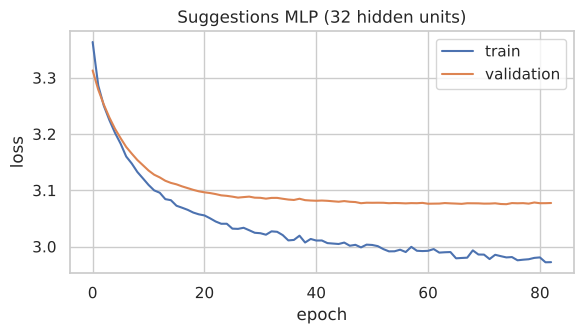

In [5]:
def build(hidden):
    inp = keras.Input(shape=(N + len(INT),), name="picked_and_interests")
    h = keras.layers.Dense(hidden, activation="relu", name="sight_embed")(inp)
    h = keras.layers.Dropout(0.2)(h)
    out = keras.layers.Dense(N, name="next_sight")(h)               # logits; softmax in the loss
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(3e-3),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))
    return model

tuning, fitted = {}, {}
for hidden in [16, 32, 64]:
    keras.utils.set_random_seed(SEED)
    m = build(hidden)
    hist = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=256, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    tuning[hidden] = {**hits(m.predict(X_val, verbose=0), X_val, y_val), "epochs": len(hist.history["loss"])}
    fitted[hidden] = (m, hist)
    print(hidden, tuning[hidden])

BEST_H = max(tuning, key=lambda h: tuning[h]["hit@3"])
mlp, hist = fitted[BEST_H]
print("chosen hidden size:", BEST_H)

plt.figure(figsize=(6, 3.5))
plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title(f"Suggestions MLP ({BEST_H} hidden units)"); plt.legend(); plt.tight_layout()
plt.show()

## 5. Compare on test trips

,"hit@3, no interests","hit@3, interests ticked","hit@1, interests ticked"
Random,0.121,0.121,0.042
Popularity,0.270,0.270,0.103
Counting (app now),0.306,0.306,0.124
Neural network (32),0.274,0.355,0.143


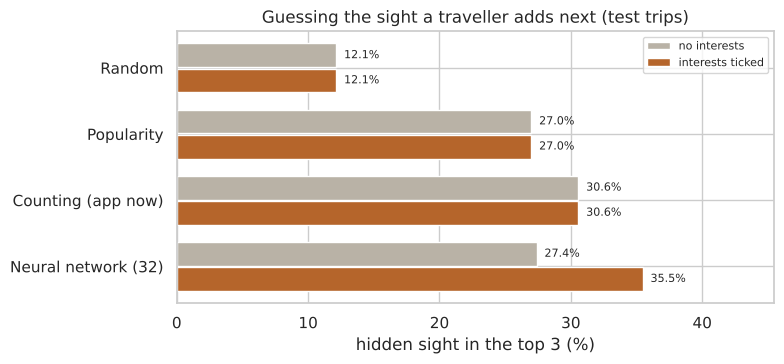

In [6]:
nn_name = f"Neural network ({BEST_H})"
h1, h0 = hits(mlp.predict(X_test, verbose=0), X_test, y_test), hits(mlp.predict(X_test0, verbose=0), X_test0, y_test)
results[nn_name] = {"hit@3, no interests": h0["hit@3"], "hit@3, interests ticked": h1["hit@3"], "hit@1, interests ticked": h1["hit@1"]}
res = pd.DataFrame(results).T
display(res.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
ypos = np.arange(len(res))
for k, (col, color) in enumerate([("hit@3, no interests", "#b9b2a6"), ("hit@3, interests ticked", "#b5652b")]):
    v = res[col] * 100
    ax.barh(ypos + (k - 0.5) * 0.38, v, height=0.36, color=color, label=col.replace("hit@3, ", ""))
    for y0, val in zip(ypos, v):
        ax.text(val + 0.6, y0 + (k - 0.5) * 0.38, f"{val:.1f}%", va="center", fontsize=8)
ax.set_yticks(ypos, res.index); ax.invert_yaxis()
ax.set_xlabel("hidden sight in the top 3 (%)"); ax.set_xlim(0, res.max().max() * 100 + 10)
ax.set_title("Guessing the sight a traveller adds next (test trips)"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(FIGS / "suggest_model.png", dpi=150); plt.show()

## 6. A few examples
The same two sights, with different interests ticked.

In [7]:
W1, b1 = mlp.get_layer("sight_embed").get_weights()
W2, b2 = mlp.get_layer("next_sight").get_weights()

def suggest(picked, likes=(), k=3):
    x = np.zeros((1, N + len(INT)), dtype="float32")
    x[0, [names.index(p) for p in picked]] = 1 / len(picked)
    x[0, [N + INT.index(l) for l in likes]] = 1
    s = mlp.predict(x, verbose=0)[0]; s[x[0, :N] > 0] = -np.inf
    return [names[j] for j in np.argsort(-s)[:k]]

for picked, likes in [(["Hagia Sophia", "Blue Mosque (Sultan Ahmed)"], []),
                      (["Hagia Sophia", "Blue Mosque (Sultan Ahmed)"], ["art"]),
                      (["Hagia Sophia", "Blue Mosque (Sultan Ahmed)"], ["sea", "views"]),
                      (["Galata Tower"], ["food", "local"]),
                      (["Galata Tower"], ["art"])]:
    print(picked, likes or "no interests", "->", suggest(picked, likes))

['Hagia Sophia', 'Blue Mosque (Sultan Ahmed)'] no interests -> ['Suleymaniye Mosque', 'Basilica Cistern', 'Topkapi Palace']
['Hagia Sophia', 'Blue Mosque (Sultan Ahmed)'] ['art'] -> ['Topkapi Palace', 'Basilica Cistern', 'Suleymaniye Mosque']
['Hagia Sophia', 'Blue Mosque (Sultan Ahmed)'] ['sea', 'views'] -> ['Galata Tower', 'Suleymaniye Mosque', "Maiden's Tower"]
['Galata Tower'] ['food', 'local'] -> ['Grand Bazaar', 'Topkapi Palace', 'Dolmabahce Palace']


['Galata Tower'] ['art'] -> ['Dolmabahce Palace', 'Istanbul Archaeology Museums', 'Grand Bazaar']


## 7. Save for the app
The app doesn't need TensorFlow: the four weight arrays go into `models/suggest_mlp.json` and the planner runs the network in the browser (one matrix multiply, ReLU, another multiply). The planner uses it only where it beat the counting method on test trips: `use_likes` when the traveller ticked interests, `use_plain` when they didn't. Otherwise it keeps counting.

In [8]:
nn, cnt = results[nn_name], results["Counting (app now)"]
use_likes = nn["hit@3, interests ticked"] > cnt["hit@3, interests ticked"]
use_plain = nn["hit@3, no interests"] > cnt["hit@3, no interests"]
r4 = lambda a: np.round(a.astype(float), 4).tolist()
out = {"W1": r4(W1), "b1": r4(b1), "W2": r4(W2), "b2": r4(b2), "names": names, "interests": INT, "hidden": BEST_H,
       "n_trips": len(trips), "n_real": len(real), "use_likes": bool(use_likes), "use_plain": bool(use_plain),
       "hit3": {"nn_likes": nn["hit@3, interests ticked"], "nn_plain": nn["hit@3, no interests"],
                "counting": cnt["hit@3, no interests"], "popularity": results["Popularity"]["hit@3, no interests"]}}
json.dump(out, open(MODELS / "suggest_mlp.json", "w"), separators=(",", ":"))
mlp.save(MODELS / "suggest_mlp.keras")
print("app uses the network: with interests", use_likes, "· without", use_plain)
print({k: round(v, 3) for k, v in out["hit3"].items()})

app uses the network: with interests True · without False
{'nn_likes': 0.355, 'nn_plain': 0.274, 'counting': 0.306, 'popularity': 0.27}


### Summary
- From the sights alone, the network is no better than counting: on these trips, pairs already carry most of the signal.
- With the ticked interests, the network gets the hidden sight into its top 3 clearly more often (section 5). That's the information counting can't use, so in the app the network ranks the suggestions when interests are ticked and counting does it otherwise.
- **Caveat:** the sample trips were generated from popularity, interests and distance, so the network is learning those rules back. The real test comes from real saved trips: re-run this notebook once the app has a few hundred, and the model learns what people actually plan.